# Swift-XRT analysis of a GRB

Set the burst in the first code cell. The download cell then fetches the UKSSDC products for that burst: the XRT position, the count-rate light curve, and the burst-analyser flux curves. Everything after that is read from those products.

Two choices are made after the curves are on the page:

- whether the early slew bins belong on the count-rate plot;
- the time after which a single decay index is fitted.

Times are seconds since the Swift trigger, unless `TIME_ZERO` is set to another clock. The flux used for the decay and for the exported light curve is the burst-analyser unabsorbed 0.3–10 keV flux, which follows the spectrum as it changes. The count-rate curve is kept as well, because that is where the WT and PC modes and the upper limits are explicit.

Run the notebook in a kernel that has `swifttools` installed (`pip install swifttools`). Products are written under `data/<GRB>/xrt/` and `results/<GRB>/`.


## 1. Setup

The next cell names the burst. `TIME_ZERO` is the only clock choice, and it can stay unset until you need this curve on the same axis as another instrument.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import swifttools.ukssdc.data.GRB as xrt
except ImportError as exc:
    raise ImportError('Install swifttools in this kernel: pip install swifttools') from exc

# Directory name, with no spaces. "GRB 260924A" and "GRB260924A" both work.
# TIME_ZERO = None keeps the Swift trigger. Set it to a MET, for example the
# GBM TRIGTIME, when this light curve has to share a time axis with that instrument.
# Z is the spectroscopic redshift. None leaves it unused.
GRB = 'GRB260924A'
Z = 3.51
TIME_ZERO = None

def swift_name(grb):
    compact = grb.replace(' ', '')
    if compact.upper().startswith('GRB'):
        return 'GRB ' + compact[3:]
    return grb

SWIFT_NAME = swift_name(GRB)
ROOT = Path.cwd()
XRT_DIR = ROOT / 'data' / GRB.replace(' ', '') / 'xrt'
LC_DIR = XRT_DIR / 'lightcurve'
BA_DIR = XRT_DIR / 'burst_analyser'
RESULTS = ROOT / 'results' / GRB.replace(' ', '')
for path in (LC_DIR, BA_DIR, RESULTS):
    path.mkdir(parents=True, exist_ok=True)

# 10 keV, the energy of the burst-analyser flux-density product.
H_KEV_S = 4.135667696e-18
FREQ_10KEV_HZ = 10.0 / H_KEV_S

def mode_of(name):
    upper = name.upper()
    if 'SLEW' in upper:
        return 'slew'
    if 'WT' in upper:
        return 'WT'
    if 'PC' in upper:
        return 'PC'
    return name

def frames(tree):
    if not isinstance(tree, dict):
        return {}
    keys = tree.get('Datasets', [key for key, value in tree.items() if isinstance(value, pd.DataFrame)])
    return {key: tree[key] for key in keys if isinstance(tree.get(key), pd.DataFrame)}

def shifted(df):
    return df['Time'].to_numpy(float) + T_OFFSET

def errors(df, pos, neg):
    return [np.abs(df[neg].to_numpy(float)), np.abs(df[pos].to_numpy(float))]

print(f'{SWIFT_NAME}    directory {XRT_DIR.parent.name}')


GRB 260924A    directory GRB260924A


## 2. Download

The UKSSDC build of a GRB light curve already chooses the binning. This cell takes that build, rather than rebinning.

- `INCLUDE_BAD_CENTROID` puts back bins the UKSSDC flagged because the source centroid failed. Leave it false. Turn it on only when the early curve has a gap and you have checked those bins by hand.
- `DROP_WT_SYSTEMATIC` removes the systematic UKSSDC adds to Windowed Timing errors. Leave it false. The systematic is part of the WT uncertainty, and dropping it makes the WT points look more precise than they are.
- `REDOWNLOAD = False` leaves files that are already in `data/<GRB>/xrt/` and reads them into memory. Nothing is fetched again. Set it true to replace those files.

The cell prints the Swift trigger in MET. If `TIME_ZERO` is set, it also prints the shift that puts the curve on that clock.


In [2]:
INCLUDE_BAD_CENTROID = False
DROP_WT_SYSTEMATIC = False
REDOWNLOAD = False

incbad = 'yes' if INCLUDE_BAD_CENTROID else 'no'
nosys = 'yes' if DROP_WT_SYSTEMATIC else 'no'

BURST_COLUMNS = [
    'Time', 'TimePos', 'TimeNeg', 'Flux', 'FluxPos', 'FluxNeg',
    'FluxPosWithECFErr', 'FluxNegWithECFErr', 'Gamma', 'GammaPos', 'GammaNeg',
    'ECF', 'ECFPos', 'ECFNeg',
]
QDP_RENAME = {
    'time': 'Time', 'tposerr': 'TimePos', 'tnegerr': 'TimeNeg',
    '+ve err': 'TimePos', '-ve err': 'TimeNeg', 'Err': 'RatePos',
    'T_+ve': 'TimePos', 'T_-ve': 'TimeNeg',
    'Ratepos': 'RatePos', 'Rateneg': 'RateNeg',
    'HRerr': 'HRErr', 'HRERR': 'HRErr', 'Harderr': 'HardErr',
}

def wanted_tags(nosys, incbad):
    tags = []
    if nosys == 'yes':
        tags.append('nosys')
    if incbad == 'yes':
        tags.append('incbad')
    return tags

def matching_products(directory, suffix, nosys, incbad):
    want = wanted_tags(nosys, incbad)
    found = []
    for path in sorted(directory.glob('*' + suffix)):
        tags = [part for part in path.stem.split('_') if part in ('nosys', 'incbad')]
        if tags == want:
            found.append(path)
    return found

def curve_key(path):
    stem = path.stem
    for tag in ('_nosys', '_incbad'):
        stem = stem.replace(tag, '')
    if stem.endswith('CURVE'):
        stem = stem[:-len('CURVE')]
    return stem

def burst_key(path):
    stem = path.stem[4:] if path.stem.startswith('XRT_') else path.stem
    for tag in ('_nosys', '_incbad'):
        stem = stem.replace(tag, '')
    return stem

def qdp_fields(line):
    if '\t' in line:
        return [part.strip() for part in line.split('\t')]
    return line.split()

def read_qdp(path):
    header = None
    rows = []
    for line in path.read_text().splitlines():
        stripped = line.strip()
        if not stripped or stripped.startswith('READ'):
            continue
        if stripped.startswith('!'):
            text = stripped[1:].strip()
            if text.lower().startswith('cols:'):
                text = text[5:].strip()
            names = [name for name in qdp_fields(text) if name]
            if names and names[0].lower().startswith('time'):
                header = names
            continue
        if stripped.upper().startswith('NO'):
            continue
        rows.append([part for part in qdp_fields(stripped) if part])
    if header is None:
        raise RuntimeError(path.name + ' has no column names.')
    if rows and len(rows[0]) == len(header) + 1 and 'Err' in header:
        at = header.index('Err')
        header = header[:at] + ['RatePos', 'RateNeg'] + header[at + 1:]
    rows = [row for row in rows if len(row) == len(header)]
    frame = pd.DataFrame(rows, columns=header).rename(columns=QDP_RENAME)
    if 'UL' in path.stem and 'Rate' in frame.columns:
        frame = frame.rename(columns={'Rate': 'UpperLimit'})
    return frame.apply(pd.to_numeric, errors='coerce')

def read_burst_table(path):
    sample = path.read_text().lstrip().split(',', 1)[0].lstrip('!')
    try:
        float(sample)
        header = None
    except ValueError:
        header = 0
    frame = pd.read_csv(path, header=header)
    if header is None:
        if frame.shape[1] != len(BURST_COLUMNS):
            raise RuntimeError(
                path.name + ' has ' + str(frame.shape[1]) + ' columns; expected '
                + str(len(BURST_COLUMNS)) + '.')
        frame.columns = BURST_COLUMNS
    return frame

def load_lightcurve(directory, nosys, incbad):
    lightcurve = {'Datasets': [], 'TimeFormat': 'seconds since the Swift trigger'}
    for path in matching_products(directory, '.qdp', nosys, incbad):
        key = curve_key(path)
        lightcurve[key] = read_qdp(path)
        lightcurve['Datasets'].append(key)
    return lightcurve

def load_burst(directory, nosys, incbad):
    xrt_data = {'Datasets': []}
    for path in matching_products(directory, '.dat', nosys, incbad):
        key = burst_key(path)
        xrt_data[key] = read_burst_table(path)
        xrt_data['Datasets'].append(key)
    return {'XRT': xrt_data}

positions = xrt.getPositions(GRBName=SWIFT_NAME, silent=False)

curve_files = matching_products(LC_DIR, '.qdp', nosys, incbad)
if curve_files and not REDOWNLOAD:
    print('Loading the light curve from ' + str(LC_DIR))
    lightcurve = load_lightcurve(LC_DIR, nosys, incbad)
else:
    lightcurve = xrt.getLightCurves(
        GRBName=SWIFT_NAME, returnData=True, saveData=True, destDir=str(LC_DIR),
        incbad=incbad, nosys=nosys, clobber=REDOWNLOAD, silent=True)
if 'NOLC' in lightcurve:
    raise RuntimeError('No XRT light curve for ' + SWIFT_NAME + '. The burst may not have been observed by the XRT.')

burst_files = matching_products(BA_DIR, '.dat', nosys, incbad)
if burst_files and not REDOWNLOAD:
    print('Loading the burst analyser from ' + str(BA_DIR))
    burst = load_burst(BA_DIR, nosys, incbad)
else:
    burst = xrt.getBurstAnalyser(
        GRBName=SWIFT_NAME, instruments=('XRT',), bands='all', returnData=True, saveData=True,
        destDir=str(BA_DIR), incbad=incbad, nosys=nosys, clobber=REDOWNLOAD, silent=True)
if 'XRT' not in burst:
    raise RuntimeError('No burst-analyser XRT products for ' + SWIFT_NAME + '. Keys: ' + str(list(burst)))

trigger_file = LC_DIR / 'trigger_met.txt'
if 'T0' in lightcurve:
    SWIFT_T0 = float(lightcurve['T0'])
    trigger_file.write_text('{:.6f}\n'.format(SWIFT_T0))
elif trigger_file.is_file():
    SWIFT_T0 = float(trigger_file.read_text())
else:
    SWIFT_T0 = None
if TIME_ZERO is None:
    T_OFFSET = 0.0
elif SWIFT_T0 is None:
    raise RuntimeError(
        'TIME_ZERO is set, but the saved products do not record the Swift trigger MET. '
        'Set REDOWNLOAD = True once so that time is written down.')
else:
    T_OFFSET = SWIFT_T0 - float(TIME_ZERO)
counts = frames(lightcurve)
spectra = frames(burst['XRT'])
if SWIFT_T0 is None:
    print('Times below are seconds since the Swift trigger. The trigger MET is not in the saved files.')
else:
    print('Swift trigger T0 = {:.3f} MET'.format(SWIFT_T0))
    if TIME_ZERO is None:
        print('Times below are seconds since the Swift trigger.')
    else:
        print('Times below are seconds since {:.3f} MET  (Swift times shifted by {:+.3f} s).'.format(TIME_ZERO, T_OFFSET))
print('Count-rate sets:', ', '.join(counts))
print('Burst-analyser sets:', ', '.join(spectra))


Resolved `GRB 260924A` as `01513082`.


Loading the light curve from /home/growth/sameer/grb_investigation/data/GRB260924A/xrt/lightcurve
Loading the burst analyser from /home/growth/sameer/grb_investigation/data/GRB260924A/xrt/burst_analyser
Times below are seconds since the Swift trigger. The trigger MET is not in the saved files.
Count-rate sets: PC, PCHR, PCUL, WT, WTHR, WTSLEW, WTSLEWHR
Burst-analyser sets: BATBand_PC, BATBand_WT, Density_PC, Density_WT, ObservedFlux_PC, ObservedFlux_WT, XRTBand_PC, XRTBand_WT


## 3. Position

Use the enhanced XRT position when it exists. It is registered to UVOT or the catalog and is the position to give the LAT analysis. The standard position is the XRT-only solution, and the onboard position is the one computed on the spacecraft. The error is the 90% confidence radius in arcseconds.


In [3]:
rows = []
for kind in ('Enhanced', 'Best', 'Standard', 'Onboard', 'SPER'):
    ra, dec, err = (positions.get(f'{kind}_RA'), positions.get(f'{kind}_Decl'), positions.get(f'{kind}_Err90'))
    if ra is None or dec is None:
        continue
    rows.append({'position': kind, 'ra': float(ra), 'dec': float(dec),
                 'err90_arcsec': float(err) if err not in (None, '') else np.nan})
position = pd.DataFrame(rows)
display(position.round(5))
preferred = position[position.position == 'Enhanced']
if preferred.empty:
    preferred = position[position.position == 'Best']
if preferred.empty:
    raise RuntimeError('The UKSSDC returned no enhanced or best position.')
POSITION = preferred.iloc[0]
print(f"Use {POSITION.position}: RA {POSITION.ra:.5f}, Dec {POSITION.dec:.5f}, "
      f"90% error {POSITION.err90_arcsec:.1f} arcsec")
position.to_csv(RESULTS / 'xrt_position.csv', index=False)


,position,ra,dec,err90_arcsec
0,Enhanced,133.76277,12.04331,1.9
1,Best,133.76277,12.04331,1.9
2,Standard,133.76180,12.04466,3.5
3,Onboard,133.76200,12.04550,5.1


Use Enhanced: RA 133.76277, Dec 12.04331, 90% error 1.9 arcsec


## 4. Count rate

Windowed Timing (WT) is the fast mode, used while the burst is bright. Photon Counting (PC) is the imaging mode, used once the rate has fallen. A step at the change of mode is a calibration residual between the two modes until you have shown it is a feature in the burst. Upper limits are the PC bins with no detection.

Slew bins are taken while Swift is still settling. Leave `SHOW_SLEW` false. Turn it on when you need the first few tens of seconds, and treat those points as less secure than the settled WT curve.


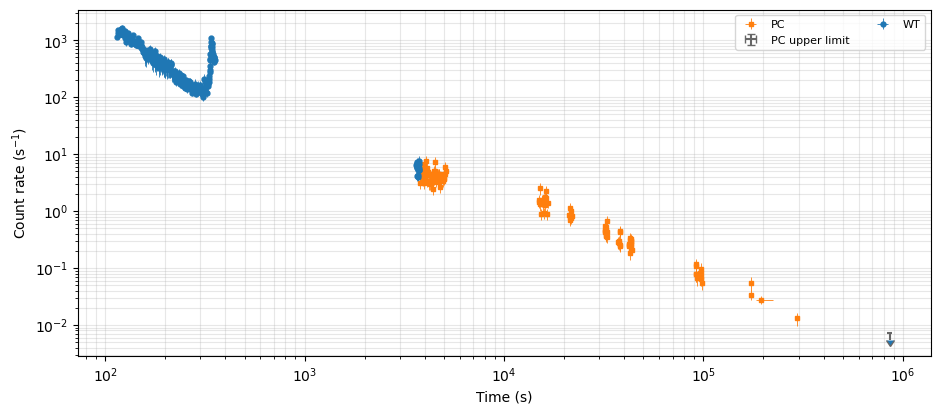

PC: 3768.8 to 293392.2 s, 129 bins
WT: 114.8 to 3749.9 s, 265 bins
WTSLEW: 100.3 to 109.6 s, 10 bins


In [4]:
SHOW_SLEW = False

fig, ax = plt.subplots(figsize=(11, 4.5))
style = {'WT': ('C0', 'o'), 'PC': ('C1', 's'), 'slew': ('C2', 'D')}
for name, df in counts.items():
    if 'Hard' in name or 'Soft' in name or name.endswith('HR'):
        continue
    kind = mode_of(name)
    if kind == 'slew' and not SHOW_SLEW:
        continue
    if name == 'PCUL':
        t = shifted(df)
        upper = df['UpperLimit'].to_numpy(float)
        keep = (t > 0) & (upper > 0)
        tn, tp = errors(df, 'TimePos', 'TimeNeg')
        ax.errorbar(t[keep], upper[keep], xerr=[tn[keep], tp[keep]],
                    yerr=0.25 * upper[keep], uplims=True, fmt='none', ecolor='0.4', label='PC upper limit')
        continue
    if 'Rate' not in df.columns:
        continue
    t = shifted(df)
    rate = df['Rate'].to_numpy(float)
    keep = (t > 0) & (rate > 0)
    color, marker = style.get(kind, ('0.3', 'o'))
    shown = df.loc[keep]
    ax.errorbar(t[keep], rate[keep], xerr=errors(shown, 'TimePos', 'TimeNeg'),
                yerr=errors(shown, 'RatePos', 'RateNeg'),
                fmt=marker, color=color, ms=3.5, lw=0.6, capsize=0, label=name)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel(r'Count rate (s$^{-1}$)')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=.3, which='both')
plt.show()

for name, df in counts.items():
    if name in ('WT', 'PC', 'WTSLEW') and len(df):
        print(f'{name}: {shifted(df).min():.1f} to {shifted(df).max():.1f} s, {len(df)} bins')


## 5. Flux and photon index

The burst analyser converts each time bin with the spectrum of that bin.

- `XRTBand` is the unabsorbed 0.3–10 keV flux, in erg cm$^{-2}$ s$^{-1}$. This is the curve to fit and to export.
- `Density` is the unabsorbed flux density at 10 keV, in Jy. It is the product that can be set beside the BAT, because 10 keV sits between the two bandpasses.
- `ObservedFlux` is the absorbed flux density at 1 keV, in Jy.
- `BATBand` is the same XRT spectrum extrapolated to 15–50 keV. It is only as good as that extrapolation.

`USE_ECF_ERR` selects the error that includes the uncertainty on the counts-to-flux factor. Leave it true whenever the flux is compared with a model. The Poisson error alone is too small once the spectrum is allowed to move.

The photon index is the power-law index used for that conversion. A jump in index at the WT to PC change should be read the same way as a jump in rate: check that it is not the mode change before calling it spectral evolution.


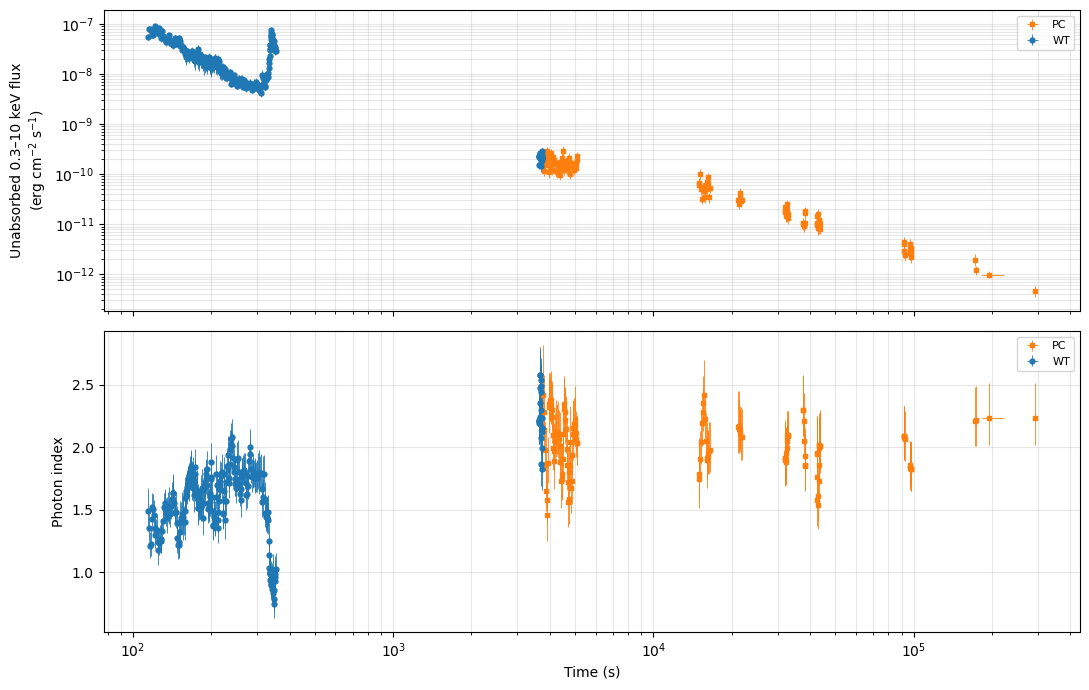

In [5]:
USE_ECF_ERR = True

def flux_columns():
    if USE_ECF_ERR:
        return 'FluxPosWithECFErr', 'FluxNegWithECFErr'
    return 'FluxPos', 'FluxNeg'

pos_col, neg_col = flux_columns()
band = {mode_of(name): df for name, df in spectra.items() if name.startswith('XRTBand')}
if not band:
    raise RuntimeError('The burst analyser did not return an XRTBand light curve.')

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for kind, df in band.items():
    color, marker = {'WT': ('C0', 'o'), 'PC': ('C1', 's'), 'slew': ('C2', 'D')}.get(kind, ('0.3', 'o'))
    t = shifted(df)
    flux = df['Flux'].to_numpy(float)
    keep = (t > 0) & (flux > 0)
    shown = df.loc[keep]
    axes[0].errorbar(t[keep], flux[keep], xerr=errors(shown, 'TimePos', 'TimeNeg'),
                     yerr=errors(shown, pos_col, neg_col),
                     fmt=marker, color=color, ms=3.5, lw=0.6, capsize=0, label=kind)
    gamma = df['Gamma'].to_numpy(float)
    axes[1].errorbar(t[keep], gamma[keep], xerr=errors(shown, 'TimePos', 'TimeNeg'),
                     yerr=errors(shown, 'GammaPos', 'GammaNeg'),
                     fmt=marker, color=color, ms=3.5, lw=0.6, capsize=0, label=kind)
axes[0].set_yscale('log')
axes[0].set_ylabel(r'Unabsorbed 0.3–10 keV flux' '\n' r'(erg cm$^{-2}$ s$^{-1}$)')
axes[1].set_ylabel('Photon index')
axes[1].set_xlabel('Time (s)')
for ax in axes:
    ax.set_xscale('log')
    ax.grid(alpha=.3, which='both')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 6. Photon index compared with the LAT

The burst analyser already records a photon index in every XRT time bin. That index is $\Gamma$ in $N(E) \propto E^{-\Gamma}$, inferred from the hardness ratio of the bin.

The LAT time series is coarser. Each of its bins is one `PowerLaw2` fit, and the notebook stores the Fermi index, which has the opposite sign. The LAT photon index plotted here is $\Gamma = -\mathrm{index}$.

To put the XRT on those same windows, the XRT indices whose bin centres fall inside a LAT bin are combined as an inverse-variance mean. The uncertainty used for the weight is the larger of the two burst-analyser errors on $\Gamma$. That mean is not a new spectral fit, and the bins are not independent, so the error bar on the mean is smaller than a joint fit would give.

Only the adaptive LAT bins (`B: bin`) with test statistic at least 25 are shown. For this burst the XRT curve starts near 115 s and is then absent until about 3600 s, so the LAT bins after that gap have no XRT mean. The figure stops at the end of the LAT window.


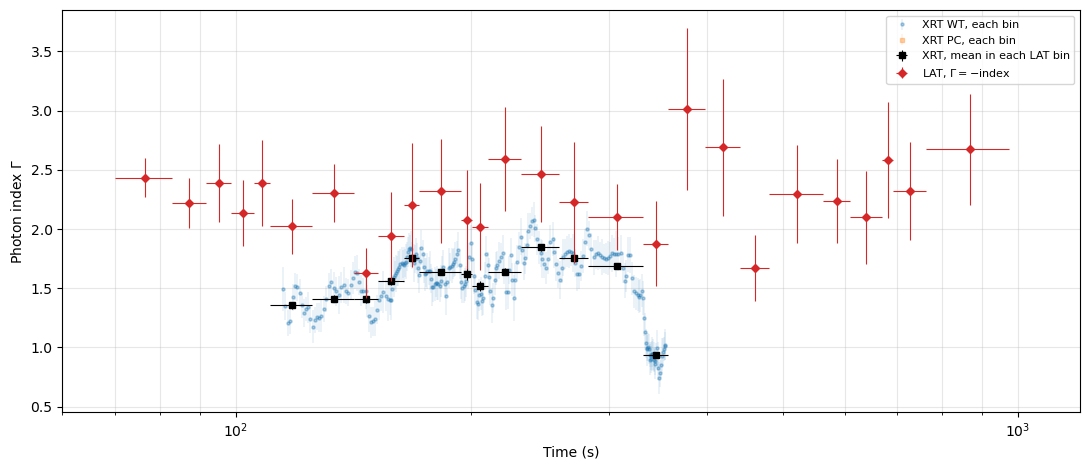

,tmin_s,tmax_s,n_xrt,xrt_gamma,xrt_gamma_err,lat_gamma,lat_gamma_err
5,110.59,125.08,13,1.36,0.03,2.02,0.23
6,125.08,141.64,18,1.41,0.03,2.30,0.25
7,141.64,151.85,12,1.41,0.04,1.63,0.21
8,151.85,163.79,17,1.56,0.03,1.94,0.38
9,163.79,171.60,15,1.76,0.03,2.21,0.52
10,171.60,194.07,33,1.64,0.02,2.32,0.44
11,194.07,200.39,7,1.62,0.05,2.08,0.42
12,200.39,209.74,11,1.52,0.04,2.02,0.37
13,209.74,231.46,22,1.64,0.03,2.59,0.44
14,231.46,258.86,21,1.85,0.03,2.47,0.41


13 LAT bins contain XRT coverage, of 27.


In [6]:
LAT_FITS = RESULTS / 'lat_fits.csv'
if not LAT_FITS.is_file():
    raise FileNotFoundError(f'{LAT_FITS} is not on disk. Run the LAT notebook first.')

lat = pd.read_csv(LAT_FITS)
lat = lat[(lat.approach == 'B: bin') & (lat.ts >= 25) & np.isfinite(lat['index'])].copy()
lat['gamma'] = -lat['index']
lat['gamma_err'] = lat['index_err']

pieces = []
for kind, df in band.items():
    part = df.copy()
    part['mode'] = kind
    part['t'] = shifted(df)
    part['gamma_err'] = np.maximum(np.abs(part['GammaPos']), np.abs(part['GammaNeg']))
    pieces.append(part)
xrt = pd.concat(pieces, ignore_index=True)
xrt = xrt[(xrt.t > 0) & np.isfinite(xrt.Gamma) & (xrt.gamma_err > 0)].copy()

rows = []
for window in lat.itertuples(index=False):
    inside = xrt[(xrt.t >= window.tmin) & (xrt.t < window.tmax)]
    if inside.empty:
        gamma, gamma_err, n = np.nan, np.nan, 0
    else:
        weight = 1.0 / inside.gamma_err.to_numpy(float) ** 2
        gamma = float(np.average(inside.Gamma.to_numpy(float), weights=weight))
        gamma_err = float(np.sqrt(1.0 / weight.sum()))
        n = int(len(inside))
    rows.append({
        'tmin_s': window.tmin, 'tmax_s': window.tmax,
        'xrt_gamma': gamma, 'xrt_gamma_err': gamma_err, 'n_xrt': n,
        'lat_gamma': window.gamma, 'lat_gamma_err': window.gamma_err, 'lat_ts': window.ts,
    })
compared = pd.DataFrame(rows)
compared.to_csv(RESULTS / 'photon_index_xrt_lat.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 4.8))
style = {'WT': ('C0', 'o'), 'PC': ('C1', 's')}
for kind, (color, marker) in style.items():
    sel = xrt[xrt['mode'] == kind]
    ax.errorbar(sel.t, sel.Gamma, yerr=sel.gamma_err, fmt=marker, color=color,
                ms=2.2, lw=0.35, alpha=0.35, capsize=0, label=f'XRT {kind}, each bin')

have = compared.n_xrt > 0
mid = 0.5 * (compared.loc[have, 'tmin_s'] + compared.loc[have, 'tmax_s'])
half = np.vstack([
    mid - compared.loc[have, 'tmin_s'],
    compared.loc[have, 'tmax_s'] - mid,
])
ax.errorbar(mid, compared.loc[have, 'xrt_gamma'], xerr=half,
            yerr=compared.loc[have, 'xrt_gamma_err'],
            fmt='s', color='k', ms=4.5, lw=0.8, capsize=0, zorder=3,
            label='XRT, mean in each LAT bin')

lat_mid = 0.5 * (lat.tmin + lat.tmax)
lat_half = np.vstack([lat_mid - lat.tmin, lat.tmax - lat_mid])
ax.errorbar(lat_mid, lat.gamma, xerr=lat_half, yerr=lat.gamma_err,
            fmt='D', color='C3', ms=4.5, lw=0.8, capsize=0, zorder=4,
            label=r'LAT, $\Gamma=-$index')

ax.set_xscale('log')
ax.set_xlim(60, 1200)
ax.set_xlabel('Time (s)')
ax.set_ylabel(r'Photon index $\Gamma$')
ax.legend(fontsize=8)
ax.grid(alpha=.3, which='both')
plt.tight_layout()
plt.show()

show = compared.loc[have, ['tmin_s', 'tmax_s', 'n_xrt', 'xrt_gamma', 'xrt_gamma_err', 'lat_gamma', 'lat_gamma_err']]
display(show.round(2))
print(f'{have.sum()} LAT bins contain XRT coverage, of {len(compared)}.')


## 7. Hardness

The repository hardness ratio is the count rate in 1.5–10 keV divided by the count rate in 0.3–1.5 keV. It is independent of the counts-to-flux conversion plotted above. A softening is a falling ratio.


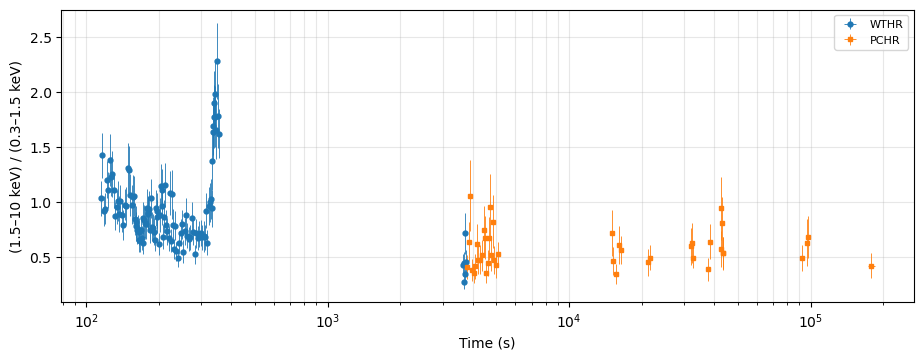

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.8))
found = False
for name, color, marker in (('WTHR', 'C0', 'o'), ('PCHR', 'C1', 's'), ('WTSLEWHR', 'C2', 'D')):
    if name not in counts or (name == 'WTSLEWHR' and not SHOW_SLEW):
        continue
    df = counts[name]
    t = shifted(df)
    keep = t > 0
    shown = df.loc[keep]
    ax.errorbar(t[keep], shown['HR'], xerr=errors(shown, 'TimePos', 'TimeNeg'),
                yerr=np.abs(shown['HRErr'].to_numpy(float)),
                fmt=marker, color=color, ms=3.5, lw=0.6, capsize=0, label=name)
    found = True
if not found:
    print('No hardness-ratio curve was returned.')
else:
    ax.set_xscale('log')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('(1.5–10 keV) / (0.3–1.5 keV)')
    ax.legend(fontsize=8)
    ax.grid(alpha=.3, which='both')
    plt.show()


## 8. Decay index

Set `DECAY_TMIN` to the start of one power-law segment, in the same time coordinate as the figures. Read that time off the unabsorbed flux curve. Place it after the steep decay and after any plateau, where the points from there to the end of the curve follow a single slope. A fit that crosses the WT to PC change mixes the mode step into the index; the cell says so when that happens.

Leave `DECAY_TMIN` as `None` until you have chosen that time. The fit is $F \propto t^{-\alpha}$, using the bin centre and the flux error selected above. Bins with a non-positive flux are left out.


In [8]:
DECAY_TMIN = None

pieces = []
for kind, df in band.items():
    part = df.copy()
    part['mode'] = kind
    part['t'] = shifted(df)
    pieces.append(part)
flux_curve = pd.concat(pieces, ignore_index=True).sort_values('t')

if DECAY_TMIN is None:
    print('DECAY_TMIN is not set. Choose the start of the decay segment from the flux curve and run this cell again.')
else:
    late = flux_curve[(flux_curve.t >= DECAY_TMIN) & (flux_curve.Flux > 0)].copy()
    if len(late) < 3:
        print(f'Only {len(late)} positive bins after {DECAY_TMIN:g} s. Move DECAY_TMIN earlier or check that the curve reaches it.')
    else:
        if late['mode'].nunique() > 1:
            print('This window contains more than one XRT mode. A step between modes will pull the index.')
        t = late.t.to_numpy(float)
        y = np.log10(late.Flux.to_numpy(float))
        sig = np.maximum(np.abs(late[pos_col]), np.abs(late[neg_col])).to_numpy(float)
        sy = sig / late.Flux.to_numpy(float) / np.log(10)
        ok = np.isfinite(sy) & (sy > 0)
        coef, cov = np.polyfit(np.log10(t[ok]), y[ok], 1, w=1 / sy[ok], cov='unscaled')
        alpha, alpha_err = -coef[0], np.sqrt(cov[0, 0])
        print(f'alpha = {alpha:.2f} ± {alpha_err:.2f} from {ok.sum()} bins after {DECAY_TMIN:g} s')
        decay = pd.DataFrame([{'tmin_s': DECAY_TMIN, 'alpha': alpha, 'alpha_err': alpha_err,
                               'n_bins': int(ok.sum()), 'modes': ','.join(sorted(late['mode'].unique()))}])
        display(decay.round(3))
        decay.to_csv(RESULTS / 'xrt_decay.csv', index=False)


DECAY_TMIN is not set. Choose the start of the decay segment from the flux curve and run this cell again.


## 9. Export

The 10 keV flux density is written in the columns used by the afterglow fits in this repository: time in seconds, flux in mJy, and the larger of the two error bars. The same error choice as the flux figure is used. The unabsorbed 0.3–10 keV curve is written beside it.


In [9]:
pieces = []
for kind, df in band.items():
    part = df.copy()
    part['mode'] = kind
    part['t'] = shifted(df)
    pieces.append(part)
flux_curve = pd.concat(pieces, ignore_index=True).sort_values('t')

density = {mode_of(name): df for name, df in spectra.items() if name.startswith('Density')}
rows = []
for kind, df in density.items():
    for row in df.itertuples(index=False):
        flux = float(row.Flux)
        err_plus = float(getattr(row, pos_col))
        err_minus = float(getattr(row, neg_col))
        if not np.isfinite(row.Time) or not np.isfinite(flux):
            continue
        if not np.isfinite(err_plus) or not np.isfinite(err_minus):
            continue
        rows.append({'Times': float(row.Time) + T_OFFSET, 'Filt': 'X-ray(10keV)', 'Freqs': FREQ_10KEV_HZ,
                     'Fluxes': flux * 1000.0, 'FluxErrs': max(abs(err_plus), abs(err_minus)) * 1000.0,
                     'UL': 'Y' if flux <= 0 else 'N', 'Instrument': 'Swift-XRT'})
density_out = pd.DataFrame(rows).sort_values('Times')
density_out.to_csv(RESULTS / 'xrt_density_10keV.csv', index=False)

flux_out = flux_curve[['t', 'mode', 'Flux', pos_col, neg_col, 'Gamma', 'GammaPos', 'GammaNeg']].rename(columns={'t': 'time_s'})
flux_out.to_csv(RESULTS / 'xrt_flux_0.3_10keV.csv', index=False)
print(f'{len(density_out)} flux-density points, 10 keV = {FREQ_10KEV_HZ:.3e} Hz')
print('Saved', RESULTS)


394 flux-density points, 10 keV = 2.418e+18 Hz
Saved /home/growth/sameer/grb_investigation/results/GRB260924A


## 10. Progenitor diagnostic (Ierardi et al. 2026)

Figure 1 of Ierardi et al. (2026, arXiv:2611.12945) is two rest-frame correlations during the X-ray steep decay and the MeV prompt. The comparison sample is the table release for that paper, [Zenodo 23613197](https://zenodo.org/records/23613197). Circles are Swift XRT+BAT steep-decay spectra. Squares are Fermi/GBM prompt spectra. Teal and blue are merger-driven candidates; orange and red are collapsar-driven candidates. GRB 211211A is the star, and GRB 200826A is brown, as in the paper.

`Ep,z = Ep (1+z)` and `nu_c,z = nu_c (1+z)` are in keV. `Liso = 4 pi d_L^2 Fbol`. The cosmology is the one in the paper: `H0 = 67.7`, `Om = 0.3`, flat.

GRB 260924A is marked from the time-resolved Band fits that already join GBM, BAT, and, once the slew is done, XRT (`results/GRB260924A/band_joint_gbm_bat_xrt.csv`). `xp` in that file is the observer-frame `nu F_nu` peak. The bolometric flux is the energy flux in the observer-frame band that corresponds to 10 keV–10 MeV in the rest frame, which is the MeV definition in the paper. The normalization pivot is 100 keV.

The same intervals are not marked on the synchrotron panel. The UKSSDC time-averaged WT spectrum (114–355 s) is a power law with photon index 1.49; a Band fit pegs the peak above the XRT band. That does not locate `nu_c`.

,bin,t_start,t_end,xrt,Ep,Ep_err_lo,Ep_err_hi,Ep_z,Ep_z_err_lo,Ep_z_err_hi,Liso,Liso_err_lo,Liso_err_hi,alpha
0,1,-11.6,40.0,False,384.4,20.773497,21.524734,1734.0,93.688471,97.076550,6.642037e+52,6.812367e+51,7.624304e+51,-0.744307
1,2,40.0,62.3,False,577.8,28.143973,30.840067,2606.0,126.929320,139.088702,1.704667e+53,1.336143e+52,1.483928e+52,-0.750706
2,3,62.3,84.8,False,915.9,29.404373,30.035592,4131.0,132.613724,135.460520,4.841346e+53,1.809536e+52,1.849225e+52,-0.871622
3,4,84.8,178.0,True,694.8,21.393334,22.591059,3134.0,96.483935,101.885678,2.163383e+53,7.470854e+51,7.923554e+51,-1.016288
4,5,178.0,260.0,True,303.3,230.801151,916.726783,1368.0,1040.913190,4134.437790,6.364316e+51,2.290864e+51,3.768946e+51,-1.640939
5,6,328.0,390.0,True,680.9,50.339956,57.355634,3071.0,227.033201,258.673911,9.837532e+52,7.884337e+51,8.841889e+51,-1.063622


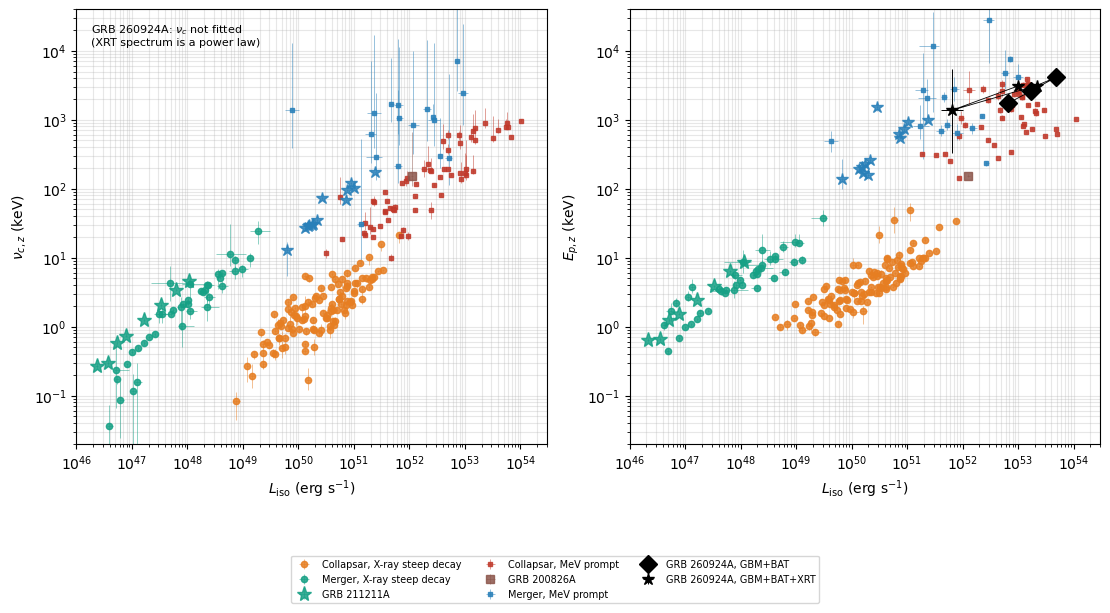

d_L = 31730 Mpc at z = 3.51
Saved /home/growth/sameer/grb_investigation/results/GRB260924A/ierardi2026_fig1.png


In [10]:
SAMPLE = ROOT / 'data' / 'ierardi2026'

def relation(name):
    return pd.read_csv(SAMPLE / name)

def clipped_err(value, err):
    return np.minimum(np.abs(err), np.abs(value) * 0.999)

def draw(ax, frame, xcol, color, marker, label, ms=4.5):
    x = frame[xcol].to_numpy(float)
    y = frame['Liso'].to_numpy(float)
    kwargs = dict(fmt=marker, color=color, ms=ms, lw=0.4, capsize=0, alpha=0.85, zorder=2)
    if label:
        kwargs['label'] = label
    ax.errorbar(
        y, x,
        xerr=[clipped_err(y, frame['Liso_err_low'].to_numpy(float)), np.abs(frame['Liso_err_high'].to_numpy(float))],
        yerr=[clipped_err(x, frame[f'{xcol}_err_low'].to_numpy(float)), np.abs(frame[f'{xcol}_err_high'].to_numpy(float))],
        **kwargs,
    )

def without(frame, names):
    return frame[~frame['GRB'].isin(names)]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.2), sharex=True)

syn = {
    'xray_col': relation('relation_syn_X-ray_collapsar.csv'),
    'xray_mer': relation('relation_syn_X-ray_merger.csv'),
    'mev_col': relation('relation_syn_MeV_collapsar.csv'),
    'mev_mer': relation('relation_syn_MeV_merger.csv'),
}
band = {
    'xray_col': relation('relation_Band_X-ray_collapsar.csv'),
    'xray_mer': relation('relation_Band_X-ray_merger.csv'),
    'mev_col': relation('relation_Band_MeV_collapsar.csv'),
    'mev_mer': relation('relation_Band_MeV_merger.csv'),
}

panels = (
    (axes[0], syn, 'nu_c_z', r'$\nu_{c,z}$ (keV)'),
    (axes[1], band, 'Ep_z', r'$E_{p,z}$ (keV)'),
)
for ax, tables, ycol, ylabel in panels:
    draw(ax, tables['xray_col'], ycol, '#e67e22', 'o', 'Collapsar, X-ray steep decay')
    mer = without(tables['xray_mer'], ['GRB211211A'])
    star = tables['xray_mer'][tables['xray_mer'].GRB == 'GRB211211A']
    draw(ax, mer, ycol, '#16a085', 'o', 'Merger, X-ray steep decay')
    if len(star):
        draw(ax, star, ycol, '#16a085', '*', 'GRB 211211A', ms=11)
    col = without(tables['mev_col'], ['bn200826187'])
    brown = tables['mev_col'][tables['mev_col'].GRB == 'bn200826187']
    draw(ax, col, ycol, '#c0392b', 's', 'Collapsar, MeV prompt', ms=3.5)
    if len(brown):
        draw(ax, brown, ycol, '#8c564b', 's', 'GRB 200826A', ms=6)
    mer = without(tables['mev_mer'], ['bn211211549'])
    star = tables['mev_mer'][tables['mev_mer'].GRB == 'bn211211549']
    draw(ax, mer, ycol, '#2980b9', 's', 'Merger, MeV prompt', ms=3.5)
    if len(star):
        draw(ax, star, ycol, '#2980b9', '*', None, ms=9)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$L_{\mathrm{iso}}$ (erg s$^{-1}$)')
    ax.set_ylabel(ylabel)
    ax.set_xlim(1e46, 3e54)
    ax.set_ylim(2e-2, 4e4)
    ax.grid(alpha=0.3, which='both')

# This burst. Band function with pivot 100 keV, as in the 3ML fits.
# Fbol is the observer-frame energy flux in the band matching 10 keV-10 MeV at rest.
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

keV_to_erg = 1.602176634e-9
PIVOT = 100.0

def band_flux(K, alpha, xp, beta, emin, emax):
    if alpha <= -2:
        return np.nan
    E0 = xp / (2.0 + alpha)
    energy = np.logspace(np.log10(emin), np.log10(emax), 4000)
    break_energy = (alpha - beta) * E0
    low = energy < break_energy
    photons = np.empty_like(energy)
    photons[low] = K * (energy[low] / PIVOT) ** alpha * np.exp(-energy[low] / E0)
    if np.any(~low):
        factor = np.exp(beta - alpha) * (break_energy / PIVOT) ** (alpha - beta)
        photons[~low] = K * factor * (energy[~low] / PIVOT) ** beta
    return np.trapezoid(photons * energy, energy) * keV_to_erg

z = Z
cosmo = FlatLambdaCDM(H0=67.7, Om0=0.3)
d_L = cosmo.luminosity_distance(z).to(u.cm).value
emin = 10.0 / (1.0 + z)
emax = 1.0e4 / (1.0 + z)

own = pd.read_csv(RESULTS / 'band_joint_gbm_bat_xrt.csv')
records = []
for row in own.itertuples(index=False):
    flux = band_flux(row.K, row.alpha, row.xp, row.beta, emin, emax)
    flux_hi = band_flux(row.K + row.K_err_hi, row.alpha, row.xp + row.xp_err_hi, row.beta, emin, emax)
    flux_lo = band_flux(max(row.K - row.K_err_lo, row.K * 0.05), row.alpha,
                        max(row.xp - row.xp_err_lo, 1.0), row.beta, emin, emax)
    scale = 4.0 * np.pi * d_L ** 2
    records.append({
        'bin': int(row.bin), 't_start': row.t_start, 't_end': row.t_end, 'xrt': bool(row.xrt),
        'Ep': row.xp, 'Ep_err_lo': row.xp_err_lo, 'Ep_err_hi': row.xp_err_hi,
        'Ep_z': row.xp * (1.0 + z),
        'Ep_z_err_lo': row.xp_err_lo * (1.0 + z), 'Ep_z_err_hi': row.xp_err_hi * (1.0 + z),
        'Liso': scale * flux, 'Liso_err_lo': scale * (flux - flux_lo), 'Liso_err_hi': scale * (flux_hi - flux),
        'alpha': row.alpha,
    })
this = pd.DataFrame(records)
this.to_csv(RESULTS / 'ierardi_fig1_this_grb.csv', index=False)
display(this.round({'Ep': 1, 'Ep_z': 0, 'Liso': 3}))

for part, marker, label in (
    (this[~this.xrt], 'D', 'GRB 260924A, GBM+BAT'),
    (this[this.xrt], '*', 'GRB 260924A, GBM+BAT+XRT'),
):
    axes[1].errorbar(
        part.Liso.to_numpy(float), part.Ep_z.to_numpy(float),
        xerr=[clipped_err(part.Liso.to_numpy(float), part.Liso_err_lo.to_numpy(float)),
              part.Liso_err_hi.to_numpy(float).clip(min=0)],
        yerr=[clipped_err(part.Ep_z.to_numpy(float), part.Ep_z_err_lo.to_numpy(float)),
              part.Ep_z_err_hi.to_numpy(float)],
        fmt=marker, color='k', ms=9, lw=0.7, capsize=0, label=label, zorder=5,
    )
axes[1].plot(this.Liso, this.Ep_z, color='k', lw=0.6, zorder=4)
axes[0].text(
    0.03, 0.97, 'GRB 260924A: $\\nu_c$ not fitted\n(XRT spectrum is a power law)',
    transform=axes[0].transAxes, va='top', ha='left', fontsize=8,
)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=7, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(RESULTS / 'ierardi2026_fig1.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'd_L = {d_L/3.085677581e24:.0f} Mpc at z = {z}')
print('Saved', RESULTS / 'ierardi2026_fig1.png')
